### Setup

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt

# Create a fresh DuckDB database from the Sakila SQLite file
duckdb_path = "data/sakila.duckdb"
Path(duckdb_path).unlink(missing_ok=True)

with duckdb.connect(duckdb_path) as conn, open("sql/load_sakila.sql") as ingest_script:
    conn.sql(ingest_script.read())
    description = conn.sql("DESC;").df()

# Load each table into a pandas DataFrame
dfs = {}
with duckdb.connect(duckdb_path) as conn:
    for name in description["name"]:
        dfs[name] = conn.sql(f"FROM {name};").df()

# Register the tables used in the analysis so duckdb.sql() can query them
table_names = ("film", "film_actor", "film_category", "actor", "category",
               "customer", "inventory", "rental", "payment")
for table_name in table_names:
    duckdb.register(table_name, dfs[table_name])

## EDA

### Movies longer than 180 minutes

In [2]:
duckdb.sql("""
SELECT title, length
FROM film
WHERE length > 180; """).df()

,title,length
0,ANALYZE HOOSIERS,181
1,BAKED CLEOPATRA,182
2,CATCH AMISTAD,183
3,CHICAGO NORTH,185
4,CONSPIRACY SPIRIT,184
5,CONTROL ANTHEM,185
6,CRYSTAL BREAKING,184
7,DARN FORRESTER,185
8,FRONTIER CABIN,183
9,GANGS PRIDE,185


### Movies that involves the word love

In [3]:
duckdb.sql("""
SELECT title, rating, length, description
FROM film
WHERE lower(title) LIKE '%love%';
""").df()


,title,rating,length,description
0,GRAFFITI LOVE,PG,117,A Unbelieveable Epistle of a Sumo Wrestler And...
1,IDAHO LOVE,PG-13,172,A Fast-Paced Drama of a Student And a Crocodil...
2,IDENTITY LOVER,PG-13,119,A Boring Tale of a Composer And a Mad Cow who ...
3,INDIAN LOVE,NC-17,135,A Insightful Saga of a Mad Scientist And a Mad...
4,LAWRENCE LOVE,NC-17,175,A Fanciful Yarn of a Database Administrator An...
5,LOVE SUICIDES,R,181,A Brilliant Panorama of a Hunter And a Explore...
6,LOVELY JINGLE,PG,65,A Fanciful Yarn of a Crocodile And a Forensic ...
7,LOVER TRUMAN,G,75,A Emotional Yarn of a Robot And a Boy who must...
8,LOVERBOY ATTACKS,PG-13,162,A Boring Story of a Car And a Butler who must ...
9,STRANGELOVE DESIRE,NC-17,103,A Awe-Inspiring Panorama of a Lumberjack And a...


### Statistic of the movies length

In [4]:
long_movies = duckdb.sql("""
SELECT
MIN(length) AS shortest,
AVG(length) AS average,
MEDIAN(length) AS median,
MAX(length) AS longest
FROM film; """).df()
long_movies.head()

,shortest,average,median,longest
0,46,115.272,114.0,185


### Top 10 expensive movies per day

In [5]:
duckdb.sql("""
SELECT 
    title,
    rental_rate / rental_duration AS cost_per_day
FROM film
ORDER BY cost_per_day DESC
LIMIT 10""").df()


,title,cost_per_day
0,AMERICAN CIRCUS,1.663333
1,BACKLASH UNDEFEATED,1.663333
2,BILKO ANONYMOUS,1.663333
3,BEAST HUNCHBACK,1.663333
4,CARIBBEAN LIBERTY,1.663333
5,AUTUMN CROW,1.663333
6,CASPER DRAGONFLY,1.663333
7,ACE GOLDFINGER,1.663333
8,BEHAVIOR RUNAWAY,1.663333
9,CASUALTIES ENCINO,1.663333


### Actors that has played in most movies

In [6]:
duckdb.sql("""
SELECT
    a.first_name || ' ' || a.last_name AS actor_name,
    COUNT(fa.film_id) AS number_of_movies
FROM actor a
JOIN film_actor fa ON a.actor_id = fa.actor_id
GROUP BY a.actor_id, actor_name
ORDER BY number_of_movies DESC, actor_name
LIMIT 10""").df()


,actor_name,number_of_movies
0,GINA DEGENERES,42
1,WALTER TORN,41
2,MARY KEITEL,40
3,MATTHEW CARREY,39
4,SANDRA KILMER,37
5,SCARLETT DAMON,36
6,ANGELA WITHERSPOON,35
7,GROUCHO DUNST,35
8,HENRY BERRY,35
9,UMA WOOD,35


### Which category has the most movies

In [7]:
duckdb.sql("""
SELECT 
    c.name AS category,
    COUNT(fc.film_id) AS number_of_movies
FROM category c
JOIN film_category fc ON c.category_id = fc.category_id
GROUP BY c.name
ORDER BY number_of_movies DESC
LIMIT 10;  """).df()

,category,number_of_movies
0,Sports,74
1,Foreign,73
2,Family,69
3,Documentary,68
4,Animation,66
5,Action,64
6,New,63
7,Drama,62
8,Sci-Fi,61
9,Games,61


### Most rented out movie

In [8]:
duckdb.sql("""
SELECT 
    f.title,
    COUNT(r.rental_id) AS rentals
FROM film f
JOIN inventory i ON f.film_id = i.film_id
JOIN rental r ON i.inventory_id = r.inventory_id
GROUP BY f.title
ORDER BY rentals DESC
LIMIT 10; """).df()

,title,rentals
0,BUCKET BROTHERHOOD,34
1,ROCKETEER MOTHER,33
2,FORWARD TEMPLE,32
3,RIDGEMONT SUBMARINE,32
4,JUGGLER HARDLY,32
5,SCALAWAG DUCK,32
6,GRIT CLOCKWORK,32
7,HOBBIT ALIEN,31
8,ZORRO ARK,31
9,NETWORK PEAK,31


### Top 5 customers

In [9]:
top5_customers = duckdb.sql("""
SELECT
    c.customer_id,
    c.first_name || ' ' || c.last_name AS name,
    SUM(p.amount) AS total_spent
FROM customer c
JOIN payment p ON c.customer_id = p.customer_id
GROUP BY c.customer_id, name
ORDER BY total_spent DESC
LIMIT 5
""").df()

top5_customers

,customer_id,name,total_spent
0,526,KARL SEAL,221.55
1,148,ELEANOR HUNT,216.54
2,144,CLARA SHAW,195.58
3,178,MARION SNYDER,194.61
4,137,RHONDA KENNEDY,194.61


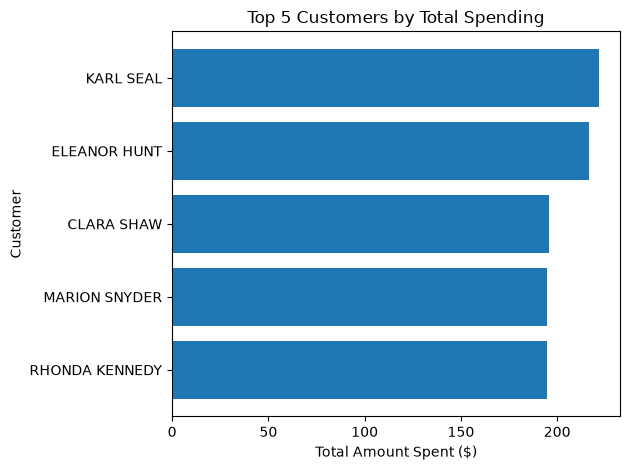

In [10]:
plt.figure()
plt.barh(top5_customers["name"], top5_customers["total_spent"])

plt.xlabel("Total Amount Spent ($)")
plt.ylabel("Customer")
plt.title("Top 5 Customers by Total Spending")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

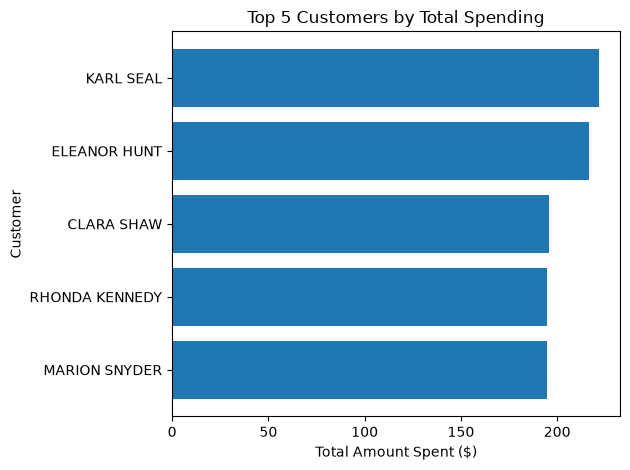

In [11]:
top5_customers = duckdb.sql("""
SELECT
    c.customer_id,
    c.first_name || ' ' || c.last_name AS name,
    SUM(p.amount) AS total_spent
FROM customer c
JOIN payment p ON c.customer_id = p.customer_id
GROUP BY c.customer_id, name
ORDER BY total_spent DESC
LIMIT 5;
""").df()

top5_customers

import matplotlib.pyplot as plt

plt.figure()
plt.barh(top5_customers["name"], top5_customers["total_spent"])

plt.xlabel("Total Amount Spent ($)")
plt.ylabel("Customer")
plt.title("Top 5 Customers by Total Spending")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Income per movie category

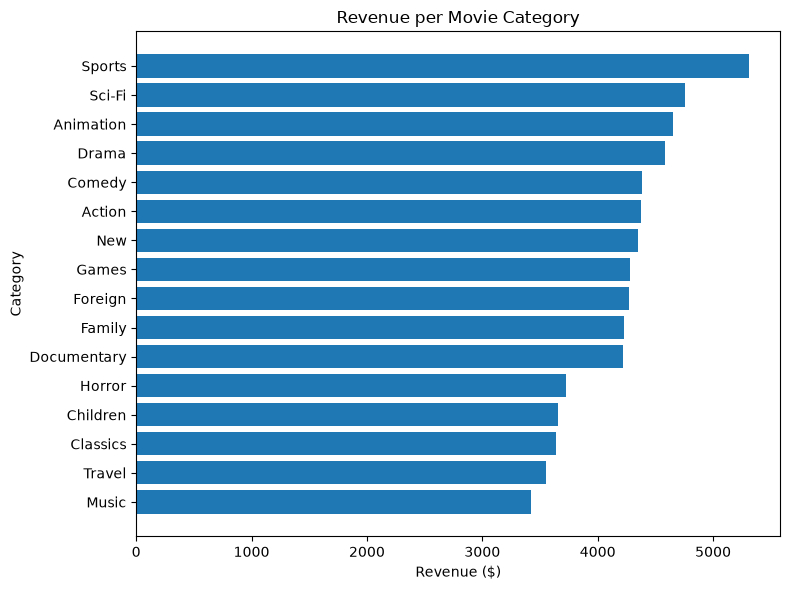

In [12]:
income_category = duckdb.sql("""
SELECT
    cat.name AS category,
    SUM(p.amount) AS revenue
FROM payment p
JOIN rental r        ON p.rental_id = r.rental_id
JOIN inventory i     ON r.inventory_id = i.inventory_id
JOIN film f          ON i.film_id = f.film_id
JOIN film_category fc ON f.film_id = fc.film_id
JOIN category cat    ON fc.category_id = cat.category_id
GROUP BY cat.name
ORDER BY revenue DESC;
""").df()

income_category

import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.barh(income_category["category"], income_category["revenue"])

plt.xlabel("Revenue ($)")
plt.ylabel("Category")
plt.title("Revenue per Movie Category")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()